<center><h1>Raza_MohammadHasnain_HW6</h1></center>
<br>
<center><font size="4">Tree-Based Methods and Class Imbalance on the APS Failure Data</font></center>

**Name:** Mohammad Hasnain Raza  
**GitHub Username:** hasnainrazaa03  
**USC ID:** 1259246355

## 1. Tree-Based Methods

Package imports

In [1]:
# all imports and dependencies
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")

# seed used for the forests, XGBoost, SMOTE and the cross-validation splits
SEED = 42

### (a) Download the APS Failure data

Each csv file starts with a 20-line license header, and missing values are written as `na`. The class column is `pos` (failure of an APS component) or `neg` (failure of some other component), and it is coded as 1/0.

In [2]:
# relative paths
TRAIN_PATH = "../data/aps_failure/aps_failure_training_set.csv"
TEST_PATH = "../data/aps_failure/aps_failure_test_set.csv"

# skip the license header
train_df = pd.read_csv(TRAIN_PATH, skiprows=20, na_values="na")
test_df = pd.read_csv(TEST_PATH, skiprows=20, na_values="na")
FEATURES = [col for col in train_df.columns if col != "class"]

# pos = 1, neg = 0
train_y = (train_df["class"] == "pos").astype(int).to_numpy()
test_y = (test_df["class"] == "pos").astype(int).to_numpy()

print("Training set:", train_df.shape, " Test set:", test_df.shape, " Features:", len(FEATURES))
train_df.head()

Training set: (60000, 171)  Test set: (16000, 171)  Features: 170


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,ag_004,ag_005,ag_006,ag_007,ag_008,ag_009,ah_000,ai_000,aj_000,ak_000,al_000,am_0,an_000,ao_000,ap_000,aq_000,ar_000,as_000,at_000,au_000,av_000,ax_000,ay_000,ay_001,ay_002,ay_003,ay_004,ay_005,ay_006,ay_007,ay_008,ay_009,az_000,az_001,az_002,az_003,az_004,az_005,az_006,az_007,az_008,az_009,ba_000,ba_001,ba_002,ba_003,ba_004,ba_005,ba_006,ba_007,ba_008,ba_009,bb_000,bc_000,bd_000,be_000,bf_000,bg_000,bh_000,bi_000,bj_000,bk_000,bl_000,bm_000,bn_000,bo_000,bp_000,bq_000,br_000,bs_000,bt_000,bu_000,bv_000,bx_000,by_000,bz_000,ca_000,cb_000,cc_000,cd_000,ce_000,cf_000,cg_000,ch_000,ci_000,cj_000,ck_000,cl_000,cm_000,cn_000,cn_001,cn_002,cn_003,cn_004,cn_005,cn_006,cn_007,cn_008,cn_009,co_000,cp_000,cq_000,cr_000,cs_000,cs_001,cs_002,cs_003,cs_004,cs_005,cs_006,cs_007,cs_008,cs_009,ct_000,cu_000,cv_000,cx_000,cy_000,cz_000,da_000,db_000,dc_000,dd_000,de_000,df_000,dg_000,dh_000,di_000,dj_000,dk_000,dl_000,dm_000,dn_000,do_000,dp_000,dq_000,dr_000,ds_000,dt_000,du_000,dv_000,dx_000,dy_000,dz_000,ea_000,eb_000,ec_00,ed_000,ee_000,ee_001,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.1307e+09,280.0,0.0,0.0,0.0,0.0,0.0,0.0,37250.0,1432864.0,3664156.0,1007684.0,25896.0,0.0,2551696.0,0.0,0.0,0.0,0.0,0.0,4933296.0,3655166.0,1766008.0,1132040.0,0.0,0.0,0.0,0.0,1012.0,268.0,0.0,0.0,0.0,0.0,0.0,469014.0,4239660.0,703300.0,755876.0,0.0,5374.0,2108.0,4114.0,12348.0,615248.0,5526276.0,2378.0,4.0,0.0,0.0,2328746.0,1022304.0,415432.0,287230.0,310246.0,681504.0,1118814.0,3574.0,0.0,0.0,6700214.0,0.0,10.0,108.0,50.0,2551696.0,97518.0,947550.0,799478.0,330760.0,353400.0,299160.0,305200.0,283680.0,NaN,NaN,NaN,178540.0,76698.08,6700214.0,6700214.0,6599892.0,43566.0,68656.0,54064.0,638360.0,6167850.0,1209600.0,246244.0,2.0,96.0,0.0,5.2458e+06,0.0,916567.68,6.0,1924.0,0.0,0.0,0.0,118196.0,1309472.0,3247182.0,1381362.0,98822.0,11208.0,1608.0,220.0,240.0,6700214.0,NaN,10476.0,1226.0,267998.0,521832.0,428776.0,4015854.0,895240.0,26330.0,118.0,0.0,532.0,734.0,4122704.0,51288.0,0.0,532572.0,0.0,18.0,5330690.0,4732.0,1126.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,62282.0,85908.0,32790.0,0.0,0.0,202710.0,37928.0,1.4746e+07,1876644.0,0.0,0.0,0.0,0.0,2.8012e+06,2445.80,2712.0,965866.0,1706908.0,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.0000e+00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,18254.0,653294.0,1720800.0,516724.0,31642.0,0.0,1393352.0,0.0,68.0,0.0,0.0,0.0,2560898.0,2127150.0,1084598.0,338544.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,71510.0,772720.0,1996924.0,99560.0,0.0,7336.0,7808.0,13776.0,13086.0,1010074.0,1873902.0,14726.0,6.0,0.0,0.0,1378576.0,447166.0,199512.0,154298.0,137280.0,138668.0,165908.0,229652.0,87082.0,4708.0,3646660.0,86.0,454.0,364.0,350.0,1393352.0,49028.0,688314.0,392208.0,341420.0,359780.0,366560.0,NaN,NaN,NaN,NaN,NaN,6700.0,33057.51,3646660.0,3646660.0,3582034.0,17733.0,260120.0,115626.0,6900.0,2942850.0,1209600.0,0.0,NaN,NaN,NaN,2.2911e+06,0.0,643536.96,0.0,0.0,0.0,0.0,38.0,98644.0,1179502.0,1286736.0,336388.0,36294.0,5192.0,56.0,NaN,0.0,3646660.0,NaN,6160.0,796.0,164860.0,350066.0,272956.0,1837600.0,301242.0,9148.0,22.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3312.0,522.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33736.0,36946.0,5936.0,0.0,0.0,103330.0,16254.0,4.5101e+06,868538.0,0.0,0.0,0.0,0.0,3.4778e+06,2211.76,2334.0,664504.0,824154.0,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.2800e+02,100.0,0.0,0.0,0.0,0.0,0.0,0.0,1648.0,370592.0,1883374.0,292936.0,12016.0,0.0,1234132.0,0.0,0.0,0.0,0.0,0.0,2371990.0,2173634.0,300796.0,153698.0,0.0,0.0,0.0,0.0,358.0,110.0,0.0,0.0,0.0,0.0,0.0,0.0,870456.0,239798.0,1450312.0,0.0,1620.0,1156.0,1228.0,34250.0,1811606.0,710672.0,34.0,0.0,0.0,0.0,790690.0,672026.0,332340.0,254892.0,189596.0,135758.0,103552.0,81666.0,46.0,0.0,2673338.0,128.0,202.0,576.0,4.0,1234132.0,28804.0,160176.0,139730.0,137160.0,130640.0

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

In [3]:
# fraction of missing values in each feature
missing = pd.DataFrame({"train": train_df[FEATURES].isna().mean(), "test": test_df[FEATURES].isna().mean()})
missing = missing.sort_values("train", ascending=False)

print(f"Training rows with at least one missing value: {train_df[FEATURES].isna().any(axis=1).mean():.2%}")
print(f"Features with missing values: {(missing['train'] > 0).sum()} of {len(FEATURES)}")
print(f"Features missing in more than half of the training rows: {(missing['train'] > 0.5).sum()}")
print(f"Missing cells in the training set: {train_df[FEATURES].isna().mean().mean():.2%}")
print(missing.head(10).to_string())

Training rows with at least one missing value: 99.02%
Features with missing values: 169 of 170
Features missing in more than half of the training rows: 8
Missing cells in the training set: 8.33%
         train    test
br_000  0.8211  0.8206
bq_000  0.8120  0.8113
bp_000  0.7957  0.7951
bo_000  0.7722  0.7735
cr_000  0.7722  0.7727
ab_000  0.7722  0.7727
bn_000  0.7335  0.7321
bm_000  0.6592  0.6591
bl_000  0.4546  0.4516
bk_000  0.3839  0.3809


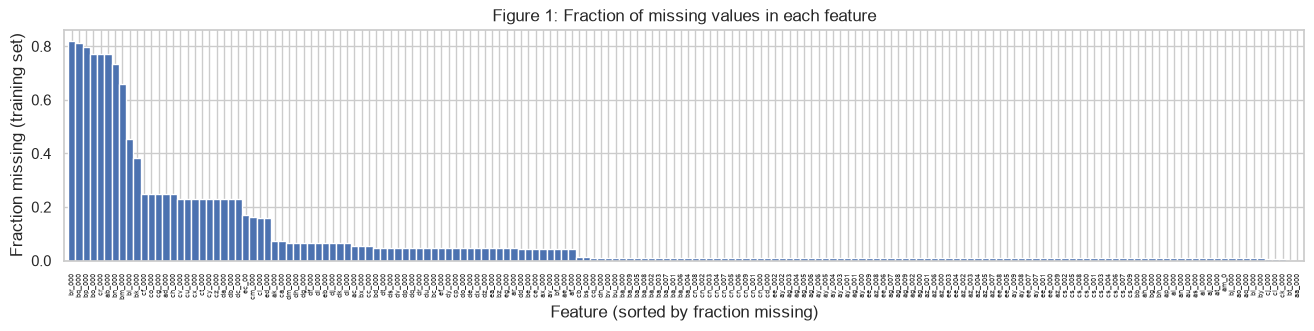

In [4]:
plt.figure(figsize=(16, 3))
plt.bar(range(len(FEATURES)), missing["train"], width=1.0)
plt.xticks(range(len(FEATURES)), missing.index, rotation=90, fontsize=5)
plt.xlim(-1, len(FEATURES))
plt.xlabel("Feature (sorted by fraction missing)")
plt.ylabel("Fraction missing (training set)")
plt.title("Figure 1: Fraction of missing values in each feature")
plt.show()

**Answer.** The usual ways to handle missing data are to drop the rows or features with missing values, fill them with a simple statistic (mean, median or mode), add a 0/1 indicator for "was missing", or predict them from the other features (regression, KNN or iterative imputation such as MICE, and multiple imputation). Some models deal with missing values on their own, like surrogate splits in CART or the default split direction in XGBoost.

Dropping rows does not work here, since **99% of the training rows have at least one missing value** and only 591 complete rows would be left. 169 of the 170 features have missing values, and 8 of them are missing in more than half of the rows (`br_000` in 82%, Figure 1). **Median imputation** is used. The features are skewed counts, so the median is a more typical value than the mean. Following footnote 1, the training set is filled with the training medians and the test set with the test medians.

In [5]:
# median imputation, each set is filled with its own medians (footnote 1)
train_X = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(train_df[FEATURES]), columns=FEATURES)
test_X = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(test_df[FEATURES]), columns=FEATURES)
print("Missing values left:", train_X.isna().sum().sum(), test_X.isna().sum().sum())

Missing values left: 0 0


#### (ii) Calculate the coefficient of variation

In [6]:
# CV = sample std / sample mean, on the imputed training set
cv_df = pd.DataFrame({"mean": train_X.mean(), "std": train_X.std(ddof=1)})
cv_df["CV"] = cv_df["std"] / cv_df["mean"]
cv_df = cv_df.sort_values("CV", ascending=False)

def sci(x):
    # 4 decimals in scientific notation, short exponent (1.4311e5 means 1.4311 x 10^5)
    return f"{x:.4e}".replace("e+0", "e").replace("e-0", "e-")

def print_side_by_side(table):
    # print the rows as two blocks next to each other
    lines = [f"{name:<7}{sci(row['mean']):>9} {sci(row['std']):>9} {row['CV']:>8.4f}" for name, row in table.iterrows()]
    half = (len(lines) + 1) // 2
    header = f"{'':<7}{'mean':>9} {'std':>9} {'CV':>8}"
    print(f"{header}  {header}")
    for left_line, right_line in zip(lines[:half], lines[half:] + [""]):
        print(f"{left_line}  {right_line}")

# all 170 features, highest CV first, in three parts
print("CV ranks 1 to 57")
print_side_by_side(cv_df.iloc[:57])

CV ranks 1 to 57
            mean       std       CV              mean       std       CV
cf_000  1.4311e5  3.5045e7 244.8875  ea_000  1.4966e0  5.2301e1  34.9465
co_000  1.4333e5  3.5045e7 244.5074  cn_009  7.7312e3  2.6496e5  34.2721
ad_000  1.4344e5  3.5045e7 244.3228  ay_004  1.0448e4  3.5264e5  33.7523
cs_009  7.7051e2  1.8333e5 237.9306  ag_009  5.0576e3  1.6871e5  33.3576
dh_000  4.3926e3  5.4124e5 123.2161  da_000  5.6922e0  1.6717e2  29.3675
dj_000  3.7271e1  4.3792e3 117.4942  ay_003  7.1450e3  2.0531e5  28.7351
ag_000  2.1916e2  2.0364e4  92.9178  cn_000  2.3099e3  6.0833e4  26.3356
as_000  1.2541e2  1.0952e4  87.3325  ae_000  6.5350e0  1.5815e2  24.2001
ay_009  1.1496e3  9.7412e4  84.7337  at_000  5.0189e3  1.1899e5  23.7082
ak_000  9.0766e2  7.2999e4  80.4250  az_008  6.5439e2  1.4841e4  22.6797
az_009  4.1603e1  3.2383e3  77.8385  dq_000  4.3236e6  9.5249e7  22.0301
ch_000 3.3333e-4 2.5818e-2  77.4539  af_000  1.0548e1  2.0539e2  19.4713
au_000  2.2816e2  1.5717e4  68.882

In [7]:
print("CV ranks 58 to 114")
print_side_by_side(cv_df.iloc[57:114])

CV ranks 58 to 114
            mean       std       CV              mean       std       CV
al_000  5.8498e4  5.3661e5   9.1731  cs_004  4.4029e5  2.0627e6   4.6848
am_0    9.2303e4  8.4506e5   9.1552  eb_000  9.1097e6  4.1357e7   4.5399
az_006  1.0076e5  8.9479e5   8.8806  de_000  3.6465e2  1.6510e3   4.5275
ag_003  8.7601e4  7.5752e5   8.6474  cn_003  5.2579e5  2.2042e6   4.1922
ct_000  6.2503e2  4.9065e3   7.8500  cg_000  8.0246e1  3.2300e2   4.0251
dy_000  7.4271e3  5.7907e4   7.7966  ax_000  3.6148e2  1.4528e3   4.0191
az_001  4.3787e3  3.3807e4   7.7209  ay_008  1.0404e6  3.9699e6   3.8157
az_003  8.6305e4  6.4965e5   7.5274  cs_001  7.8365e2  2.8705e3   3.6631
bf_000  7.1842e1  5.3547e2   7.4535  dv_000  5.6824e5  2.0385e6   3.5874
bc_000  5.4439e2  3.9547e3   7.2644  bj_000  5.0660e5  1.8115e6   3.5758
dr_000  1.9450e5  1.3353e6   6.8654  ay_007  1.5326e6  5.0791e6   3.3140
be_000  1.3229e3  9.0581e3   6.8472  ee_000  7.2812e5  2.4031e6   3.3005
ba_008  3.5472e4  2.4229e5   6.8

In [8]:
print("CV ranks 115 to 170")
print_side_by_side(cv_df.iloc[114:])

CV ranks 115 to 170
            mean       std       CV              mean       std       CV
ag_007  4.9506e5  1.4154e6   2.8590  ag_006  1.6497e6  3.8882e6   2.3569
aq_000  4.3982e5  1.2565e6   2.8569  cn_005  1.3338e6  3.1273e6   2.3448
az_004  1.4613e6  4.1632e6   2.8490  ds_000  8.7759e4  2.0360e5   2.3200
ee_005  3.9167e5  1.1150e6   2.8467  ah_000  1.8013e6  4.1640e6   2.3117
ba_007  1.8371e5  5.2249e5   2.8441  ac_000  3.3623e8  7.7676e8   2.3102
ba_003  2.7240e5  7.4438e5   2.7327  bg_000  1.8008e6  4.1586e6   2.3093
ba_000  1.3914e6  3.7562e6   2.6996  ce_000  6.1803e4  1.4037e5   2.2712
ba_005  1.8774e5  5.0646e5   2.6977  ao_000  2.9891e6  6.7873e6   2.2707
ba_004  2.0369e5  5.3607e5   2.6317  an_000  3.4445e6  7.7502e6   2.2500
bh_000  5.7605e4  1.5143e5   2.6287  dt_000  1.5081e4  3.3057e4   2.1919
ba_001  8.8895e5  2.3330e6   2.6244  do_000  2.7685e4  5.9967e4   2.1661
ee_004  4.4323e5  1.1620e6   2.6217  cs_006  5.4237e5  1.1621e6   2.1426
cn_004  1.2741e6  3.3390e6   2.

**Answer.** The top three, `cf_000`, `co_000` and `ad_000` (CV about 245), are high because of **one training row** (row 45977) with a value of about $8.58 \times 10^9$ in all three. Without that row their CVs are about 34, 9 and 8. Most of the other high-CV features are counters or histogram bins that are 0 for almost every truck. `cd_000` has the same value for every truck, so its CV is 0 and it carries no information. Most of the lowest CVs (below 1) are in the `bk_000` to `br_000` group, partly because so many of their values were filled with the same median.

#### (iii) Plot a correlation matrix

Constant features: ['cd_000']


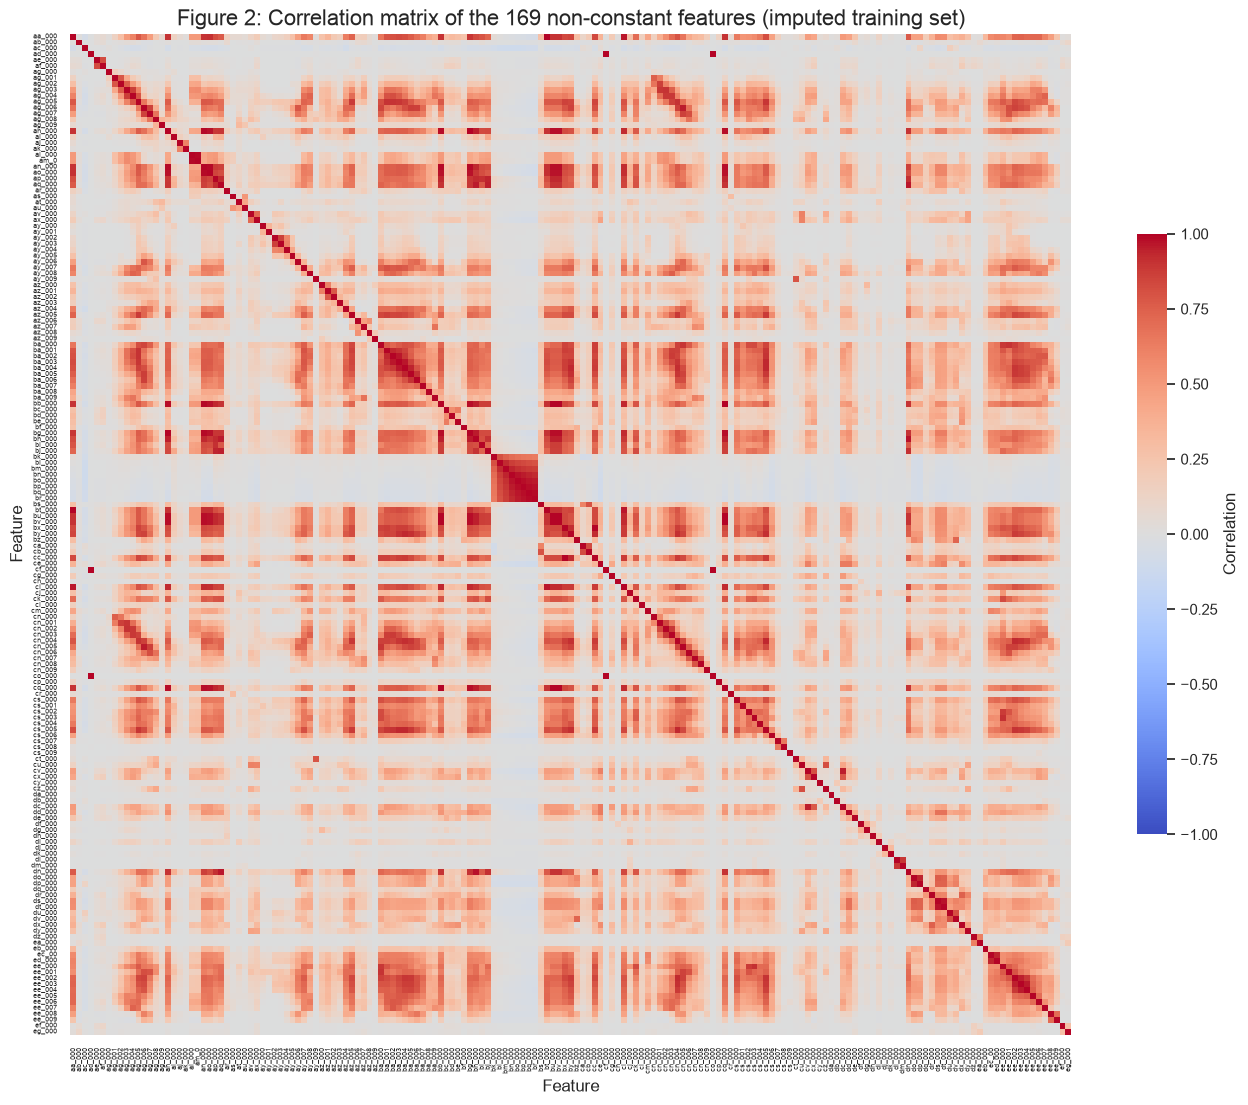

In [9]:
# cd_000 is constant, so its correlations are undefined and it is left out of the plot
CONSTANT = [col for col in FEATURES if train_X[col].nunique() == 1]
print("Constant features:", CONSTANT)
corr = train_X.drop(columns=CONSTANT).corr()

plt.figure(figsize=(17, 13))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, xticklabels=True, yticklabels=True, cbar_kws={"shrink": 0.6, "label": "Correlation"})
plt.tick_params(labelsize=5)
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.title("Figure 2: Correlation matrix of the 169 non-constant features (imputed training set)", fontsize=16)
plt.show()

In [10]:
# strongest feature pairs (upper triangle only)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
print(f"Pairs with |r| > 0.9: {(upper.abs() > 0.9).sum()} of {len(upper)}")
print(upper.reindex(upper.abs().sort_values(ascending=False).index).head(10).to_frame("correlation").to_string())

Pairs with |r| > 0.9: 130 of 14196
               correlation
bv_000 cq_000       1.0000
bu_000 cq_000       1.0000
       bv_000       1.0000
cf_000 co_000       1.0000
ad_000 cf_000       1.0000
       co_000       1.0000
aa_000 bt_000       0.9988
ah_000 bg_000       0.9977
bb_000 bv_000       0.9963
       bu_000       0.9963


**Answer.** Most features are positively correlated, and 130 of the 14196 pairs have $|r| > 0.9$. The large red blocks in Figure 2 are the counters and histogram bins (`ag_*`, `ay_*`, `az_*`, `ba_*`, `cn_*`, `cs_*`, `ee_*`), which all grow with how much a truck is used. Some features are near copies: `bu_000`, `bv_000` and `cq_000` have $r = 1.00$, and `cf_000`, `co_000` and `ad_000` have $r = 1.00$ because of the outlier row from (ii). The `bk_000` to `br_000` block is correlated within itself but not with the rest. No pair is strongly negative (the lowest $r$ is $-0.11$).

#### (iv) Make scatter plots and box plots

The features are heavy-tailed counts and histogram bins (most values are near 0 and a few are in the millions), so the plots use $\log_{10}(1 + x)$ to make them readable. The positive class is drawn on top.

13 ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


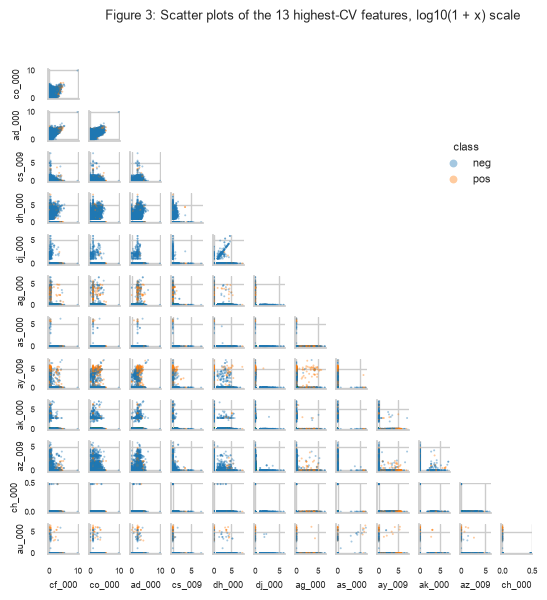

In [11]:
# floor(sqrt(170)) = 13 features with the highest CV
n_top = int(np.floor(np.sqrt(170)))
top_features = list(cv_df.index[:n_top])
print(n_top, top_features)

top_df = np.log10(1 + train_X[top_features])
top_df["class"] = train_df["class"]

sns.set_context("notebook", font_scale=0.55)
pair_grid = sns.pairplot(top_df, hue="class", hue_order=["neg", "pos"], palette={"neg": "tab:blue", "pos": "tab:orange"}, height=0.45, corner=True, diag_kind=None, plot_kws={"s": 2, "alpha": 0.4, "linewidth": 0})
# the diagonal would only plot each feature against itself
for i in range(n_top):
    pair_grid.axes[i, i].set_visible(False)
sns.move_legend(pair_grid, "upper right", bbox_to_anchor=(0.8, 0.8), markerscale=4, fontsize=8, title_fontsize=8)
pair_grid.figure.suptitle(f"Figure 3: Scatter plots of the {n_top} highest-CV features, log10(1 + x) scale", y=1.01, fontsize=9)
plt.show()
sns.set_context("notebook")

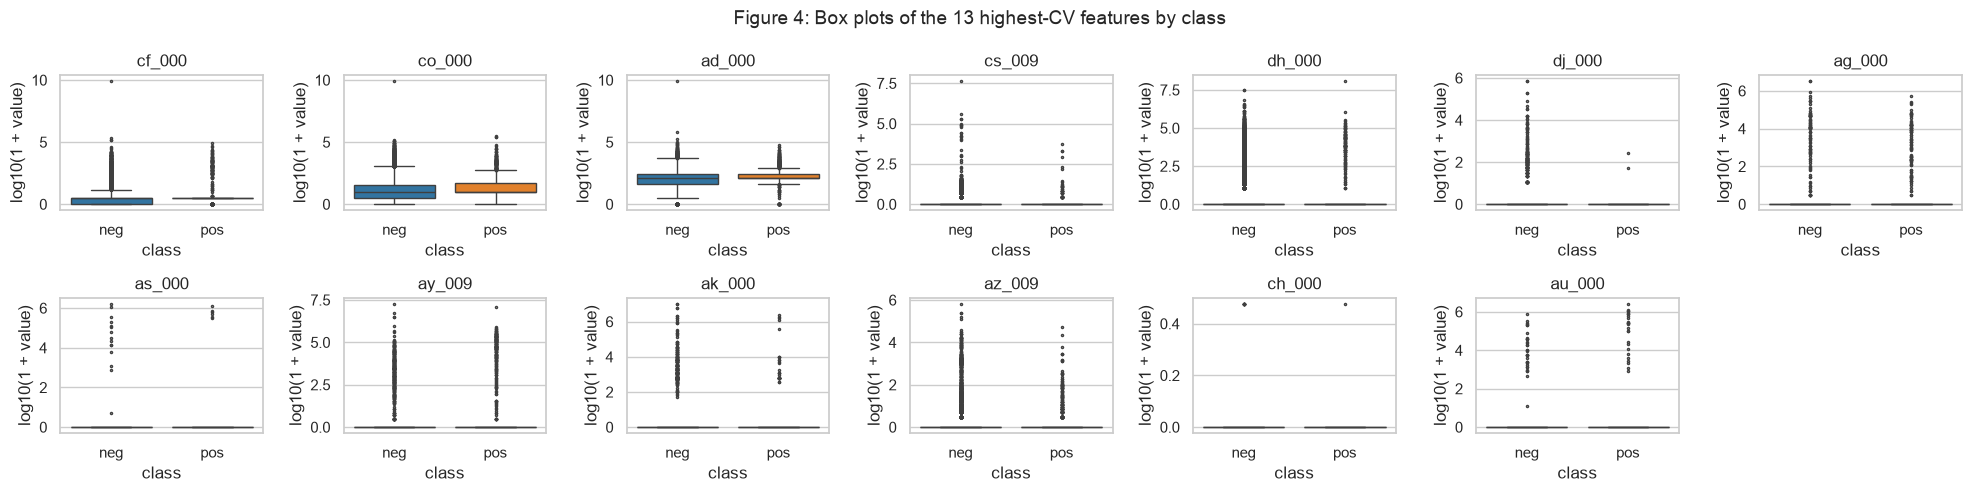

In [12]:
# box plots of each feature by class
fig, axes = plt.subplots(2, 7, figsize=(20, 5))
for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(x=top_df["class"], y=top_df[feature], order=["neg", "pos"], hue=top_df["class"], palette={"neg": "tab:blue", "pos": "tab:orange"}, fliersize=1.5, ax=ax)
    ax.set(xlabel="class", ylabel="log10(1 + value)", title=feature)
axes.flat[-1].axis("off")
fig.suptitle(f"Figure 4: Box plots of the {n_top} highest-CV features by class", fontsize=14)
plt.tight_layout()
plt.show()

In [13]:
# median of each feature in each class, and how often it is 0
class_medians = pd.DataFrame({
    "median (neg)": train_X.loc[train_y == 0, top_features].median(),
    "median (pos)": train_X.loc[train_y == 1, top_features].median(),
    "zero fraction (neg)": (train_X.loc[train_y == 0, top_features] == 0).mean(),
    "zero fraction (pos)": (train_X.loc[train_y == 1, top_features] == 0).mean(),
})
print(class_medians.to_string())

        median (neg)  median (pos)  zero fraction (neg)  zero fraction (pos)
cf_000           2.0           2.0               0.3604                0.204
co_000           8.0           8.0               0.2162                0.036
ad_000         126.0         126.0               0.0336                0.027
cs_009           0.0           0.0               0.9517                0.948
dh_000           0.0           0.0               0.8836                0.881
dj_000           0.0           0.0               0.9967                0.998
ag_000           0.0           0.0               0.9983                0.903
as_000           0.0           0.0               0.9997                0.994
ay_009           0.0           0.0               0.9944                0.793
ak_000           0.0           0.0               0.9942                0.969
az_009           0.0           0.0               0.9711                0.823
ch_000           0.0           0.0               0.9998                0.999

**Answer.** **No, the scatter plots are not enough to judge significance.** For `cf_000`, `co_000` and `ad_000` the two classes overlap completely, and the other ten features are 0 for most trucks in both classes, so their plots are mostly points piled up on the axes. In Figure 4 the medians are the same for both classes for all 13 features.

Some features do look useful. Non-zero values are much more common among failures, for example `ag_000` is non-zero for 9.7% of the positive trucks against 0.2% of the negative ones, and `ay_009` for 20.7% against 0.6%. But a scatter plot only shows one or two features at a time, while significance is about a feature's effect given the others, which needs a fitted model and a test. A high CV also just means a large spread, not a link to the class.

#### (v) Is this data set imbalanced?

In [14]:
class_counts = pd.DataFrame({"training": train_df["class"].value_counts(), "test": test_df["class"].value_counts()})
print(class_counts.to_string())
print("positive fraction:", (class_counts.loc["pos"] / class_counts.sum()).round(4).to_dict())

       training   test
class                 
neg       59000  15625
pos        1000    375
positive fraction: {'training': 0.0167, 'test': 0.0234}


**Answer.** The training set has **59000 negative and 1000 positive** trucks (1.67% positive) and the test set has 15625 negative and 375 positive (2.34%). **Yes, it is heavily imbalanced.** Calling every truck negative would already give a training error of only 1.67% while missing every failure, so the error rate alone is not a good measure here. The test set has a larger share of positives, so test errors should come out a little higher than CV or OOB errors.

### (c) Train a random forest

The same helper functions are used for every model in (c) to (f). A truck is predicted positive when its predicted probability is at least 0.5. The challenge cost from `aps_failure_description.txt` is also reported: 10 for each false positive (an unnecessary check) and 500 for each false negative (a missed failure). Each model gets one figure with its training and test confusion matrices (with the error) and ROC curves (with the AUC). All scores are collected in the summary table in (f).

In [15]:
def scores(y, prob):
    # error, AUC and confusion counts at the 0.5 threshold
    tn, fp, fn, tp = confusion_matrix(y, (prob >= 0.5).astype(int)).ravel()
    return {"error (%)": 100 * (fp + fn) / len(y), "AUC": roc_auc_score(y, prob), "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn), "recall (%)": 100 * tp / (tp + fn), "cost": int(10 * fp + 500 * fn)}

def confusion_table(y, prob):
    table = confusion_matrix(y, (prob >= 0.5).astype(int))
    return pd.DataFrame(table, index=["neg", "pos"], columns=["neg", "pos"])

def report(model, name, X_train, X_test, title):
    # confusion matrices, errors and ROC curves on the training and test sets
    train_prob = model.predict_proba(X_train)[:, 1]
    test_prob = model.predict_proba(X_test)[:, 1]
    results[name] = {"train": scores(train_y, train_prob), "test": scores(test_y, test_prob)}
    for key in ["train", "test"]:
        res = results[name][key]
        print(f"{key:<5}  error = {res['error (%)']:.4f}%, AUC = {res['AUC']:.4f}, recall = {res['recall (%)']:.4f}%, cost = {res['cost']}")

    fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
    for ax, y, prob, label, key in [(axes[0], train_y, train_prob, "Training", "train"), (axes[1], test_y, test_prob, "Test", "test")]:
        sns.heatmap(confusion_table(y, prob), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
        ax.set(title=f"{label} confusion matrix (error {results[name][key]['error (%)']:.3f}%)", xlabel="Predicted class", ylabel="True class")
        fpr, tpr, _ = roc_curve(y, prob)
        axes[2].plot(fpr, tpr, label=f"{label} (AUC = {roc_auc_score(y, prob):.4f})")
    axes[2].plot([0, 1], [0, 1], "k:", lw=1)
    axes[2].set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate")
    axes[2].legend(loc="lower right")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    return test_prob

# scores of every model, used for the comparisons
results = {}
test_probs = {}

train  error = 0.0000%, AUC = 1.0000, recall = 100.0000%, cost = 0
test   error = 0.7625%, AUC = 0.9943, recall = 72.5333%, cost = 51690


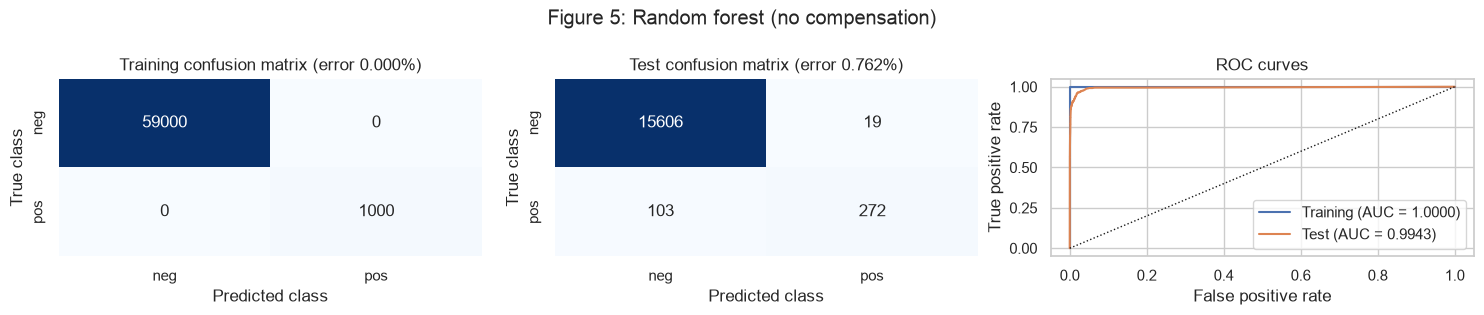

OOB error = 0.580%, test error = 0.762%


In [16]:
# random forest with no compensation for class imbalance
rf = RandomForestClassifier(n_estimators=500, oob_score=True, n_jobs=-1, random_state=SEED).fit(train_X, train_y)
test_probs["Random forest"] = report(rf, "Random forest", train_X, test_X, "Figure 5: Random forest (no compensation)")

rf_oob = 100 * (1 - rf.oob_score_)
print(f"OOB error = {rf_oob:.3f}%, test error = {results['Random forest']['test']['error (%)']:.3f}%")

**Answer.** The training results are perfect (0 errors, AUC 1.0000) because the trees are grown until every leaf is pure, so they say nothing about new trucks. On the test set the AUC is high (0.9943), so the forest ranks trucks well, but at the 0.5 threshold it **misses 103 of the 375 failures** (recall 72.5%). The **OOB error (0.580%) is close to the test error (0.762%)**, since each tree is scored only on the rows left out of its bootstrap sample. It is a bit lower mostly because the test set has more positives, and that is where the errors are.

### (d) Research class imbalance in random forest

**Answer.** Chen, Liaw and Breiman (2004) give two main fixes. A **weighted random forest** gives the minority class a larger weight (here 59 to 1), which is used in the Gini criterion and in the vote of each leaf. A **balanced random forest** grows each tree on a bootstrap sample of the minority class plus the same number of rows drawn from the majority class. Other options are oversampling the minority class (for example SMOTE, as in part (f)) and moving the classification threshold. Both of the first two are fit below, with 500 trees each as in (c).

train  error = 0.0000%, AUC = 1.0000, recall = 100.0000%, cost = 0
test   error = 1.0750%, AUC = 0.9943, recall = 57.6000%, cost = 79630


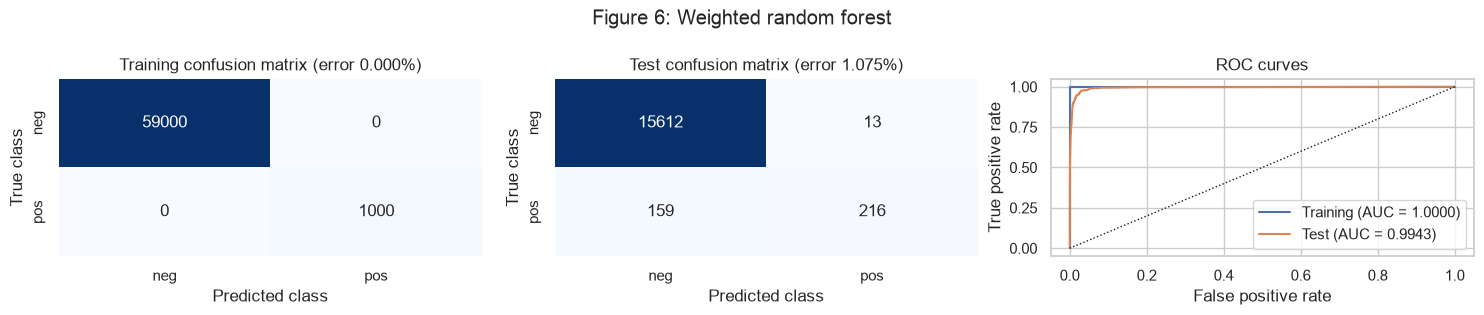

OOB error = 0.753%, test error = 1.075%


In [17]:
# weighted random forest: class weights recomputed on each bootstrap sample
weighted_rf = RandomForestClassifier(n_estimators=500, class_weight="balanced_subsample", oob_score=True, n_jobs=-1, random_state=SEED).fit(train_X, train_y)
test_probs["Weighted random forest"] = report(weighted_rf, "Weighted random forest", train_X, test_X, "Figure 6: Weighted random forest")

weighted_oob = 100 * (1 - weighted_rf.oob_score_)
print(f"OOB error = {weighted_oob:.3f}%, test error = {results['Weighted random forest']['test']['error (%)']:.3f}%")

In the balanced random forest each tree is grown on a bootstrap sample of the 1000 positive rows plus 1000 negative rows drawn with replacement. A training row is out of bag for a tree when it was not drawn for that tree, so the OOB error is computed from the rows each tree's sampler drew.

train  error = 4.2867%, AUC = 0.9983, recall = 100.0000%, cost = 25720
test   error = 4.1562%, AUC = 0.9930, recall = 98.1333%, cost = 10080


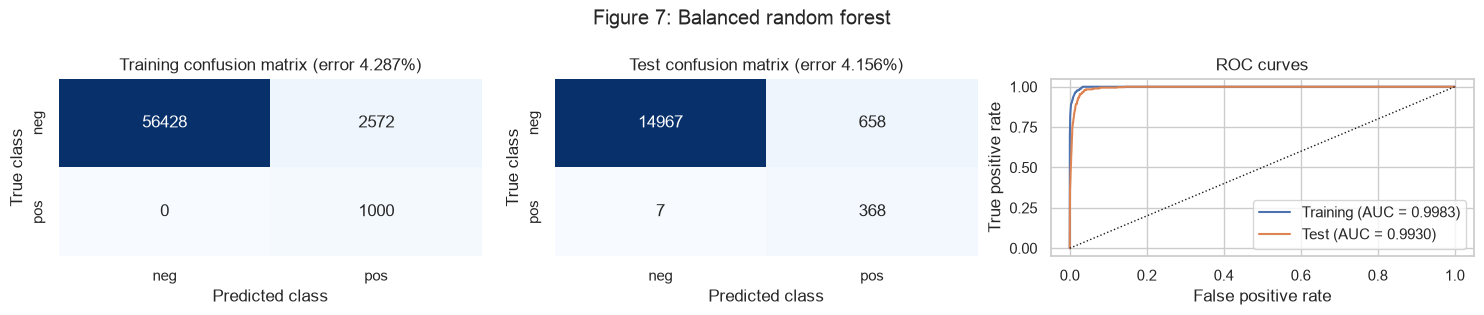

OOB error = 4.425%, test error = 4.156%


In [18]:
# balanced random forest (Chen, Liaw and Breiman, 2004)
balanced_rf = BalancedRandomForestClassifier(n_estimators=500, sampling_strategy="all", replacement=True, bootstrap=False, n_jobs=-1, random_state=SEED).fit(train_X, train_y)

def balanced_oob_error(forest, X, y):
    # average the trees for which each row is out of bag
    prob_sum = np.zeros(len(y))
    n_trees = np.zeros(len(y))
    for sampler, tree in zip(forest.samplers_, forest.estimators_):
        oob = np.ones(len(y), dtype=bool)
        oob[sampler.sample_indices_] = False
        prob_sum[oob] += tree.predict_proba(X[oob])[:, 1]
        n_trees[oob] += 1
    return 100 * np.mean((prob_sum / n_trees >= 0.5) != y)

test_probs["Balanced random forest"] = report(balanced_rf, "Balanced random forest", train_X, test_X, "Figure 7: Balanced random forest")

balanced_oob = balanced_oob_error(balanced_rf, train_X.to_numpy(), train_y)
print(f"OOB error = {balanced_oob:.3f}%, test error = {results['Balanced random forest']['test']['error (%)']:.3f}%")

**Answer.** The numbers are in Figures 5 to 7 and in the summary table in (f). **Class weights alone do not help.** The leaves are still pure, so each leaf votes for one class no matter the weights, and the weighted forest misses even more failures (159) with a higher test error (1.075%). The balanced forest finds 368 of the 375 failures (recall 98.1%), but it also raises 658 false alarms. Its test error goes up to 4.16%, but a missed failure costs 500 and a false alarm only 10, so its **cost drops by 80%** (from 51690 to 10080). That is close to the best challenge score of 9920 given in the data description. The AUC is about the same for all three forests, so compensation mostly moves the operating point along the ROC curve (Figures 5 to 7). The OOB error of the balanced forest (4.43%) is again close to its test error.

### (e) XGBoost and Model Trees

XGBoost fits an additive model on the log-odds scale, so the boosted trees together form a logistic regression whose terms are trees, and each tree is fit to the gradient of the logistic loss. `reg_alpha` adds an L1 penalty $\alpha \sum |w|$ on the leaf weights $w$ of each tree. The other settings are fixed (300 trees, learning rate 0.1, depth 6), and $\alpha$ is chosen by the lowest 5-fold stratified CV error. The CV AUC is shown too.

chosen alpha = 0.01, CV error = 0.518%
  alpha  CV error (%)  CV AUC
  0.000        0.5217  0.9890
  0.001        0.5367  0.9891
  0.010        0.5183  0.9885
  0.100        0.5400  0.9888
  1.000        0.5383  0.9893
 10.000        0.7117  0.9893
100.000        1.0983  0.9820


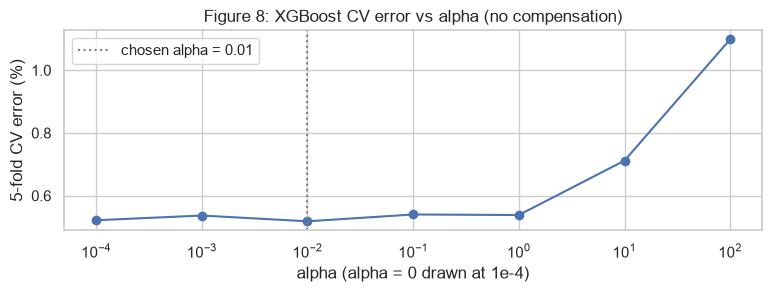

In [19]:
# 5-fold stratified CV split used for all tuning
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
REG_ALPHAS = [0, 0.001, 0.01, 0.1, 1, 10, 100]
CV_SCORING = {"accuracy": "accuracy", "AUC": "roc_auc"}

def xgb_model():
    return XGBClassifier(objective="binary:logistic", n_estimators=300, learning_rate=0.1, max_depth=6, random_state=SEED, n_jobs=1)

def cv_table(search):
    # CV error and AUC for each alpha
    return pd.DataFrame({"alpha": REG_ALPHAS, "CV error (%)": 100 * (1 - search.cv_results_["mean_test_accuracy"]), "CV AUC": search.cv_results_["mean_test_AUC"]})

def plot_cv(table, best, title):
    # alpha = 0 is drawn at 1e-4 on the log axis
    plot_alphas = [a if a > 0 else 1e-4 for a in table["alpha"]]
    plt.figure(figsize=(9, 2.6))
    plt.semilogx(plot_alphas, table["CV error (%)"], marker="o")
    plt.axvline(best if best > 0 else 1e-4, color="gray", ls=":", label=f"chosen alpha = {best}")
    plt.xlabel("alpha (alpha = 0 drawn at 1e-4)")
    plt.ylabel("5-fold CV error (%)")
    plt.title(title)
    plt.legend()
    plt.show()

xgb_search = GridSearchCV(xgb_model(), {"reg_alpha": REG_ALPHAS}, cv=folds, scoring=CV_SCORING, refit="accuracy", n_jobs=-1).fit(train_X, train_y)
xgb_alpha = xgb_search.best_params_["reg_alpha"]
xgb_cv_table = cv_table(xgb_search)
xgb_cv_error = xgb_cv_table.loc[xgb_search.best_index_, "CV error (%)"]
print(f"chosen alpha = {xgb_alpha}, CV error = {xgb_cv_error:.3f}%")
print(xgb_cv_table.to_string(index=False))
plot_cv(xgb_cv_table, xgb_alpha, "Figure 8: XGBoost CV error vs alpha (no compensation)")

train  error = 0.0017%, AUC = 1.0000, recall = 99.9000%, cost = 500
test   error = 0.5875%, AUC = 0.9952, recall = 79.2000%, cost = 39160


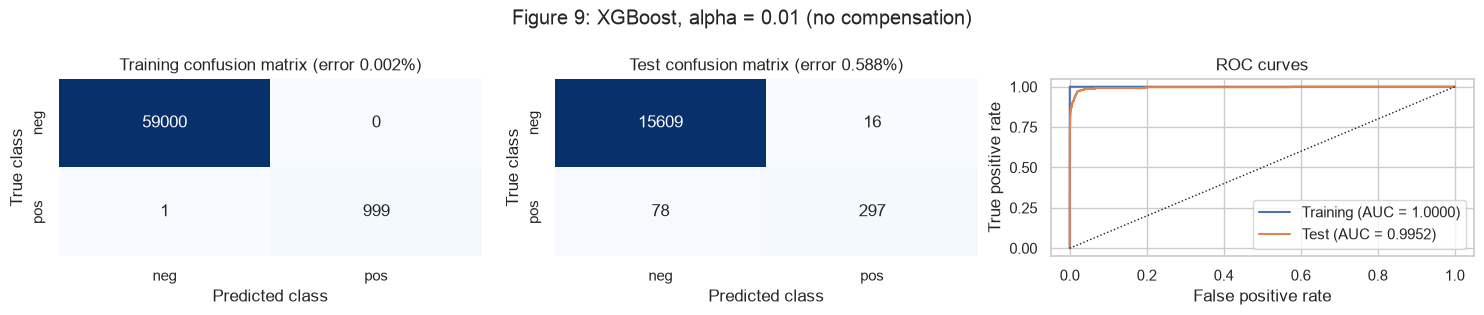

CV error = 0.518%, test error = 0.588%


In [20]:
# refit on the whole training set with the chosen alpha
test_probs["XGBoost"] = report(xgb_search.best_estimator_, "XGBoost", train_X, test_X, f"Figure 9: XGBoost, alpha = {xgb_alpha} (no compensation)")
print(f"CV error = {xgb_cv_error:.3f}%, test error = {results['XGBoost']['test']['error (%)']:.3f}%")

**Answer.** CV picks **alpha = 0.01**. Figure 8 shows the CV error is almost flat for alpha from 0 to 1 and only goes up at 10 and 100, where the penalty is too strong and the model underfits.

The **CV error (0.518%) is close to the test error (0.588%)**, and again the small gap fits the larger share of positives in the test set. On the training set it makes only 1 mistake (error 0.002%). This model has the lowest test error and the highest test AUC (0.9952) of all the models, and it misses fewer failures than the random forest in (c) (78 against 103). Without compensation it still misses about one failure in five (cost 39160).

### (f) Use SMOTE to pre-process your data

SMOTE makes new positive rows on the line between a positive row and one of its 5 nearest positive neighbours (found with Euclidean distance, so the features are standardized first, which does not change the trees), until both classes have 59000 rows. **Right way:** SMOTE sits inside the pipeline, so in each CV split it only sees the 4 training folds and the held-out fold keeps its real rows. **Wrong way:** SMOTE is applied to the whole training set before CV, so synthetic rows made from training-fold rows end up in the held-out folds and the CV error is too optimistic. Both are shown below, with SMOTE on the full training set.

chosen alpha = 0.001, CV error = 0.623%
  alpha  CV error (%)  CV AUC
  0.000        0.6417  0.9872
  0.001        0.6233  0.9873
  0.010        0.6250  0.9872
  0.100        0.6333  0.9871
  1.000        0.6350  0.9871
 10.000        0.7950  0.9876
100.000        1.8850  0.9862


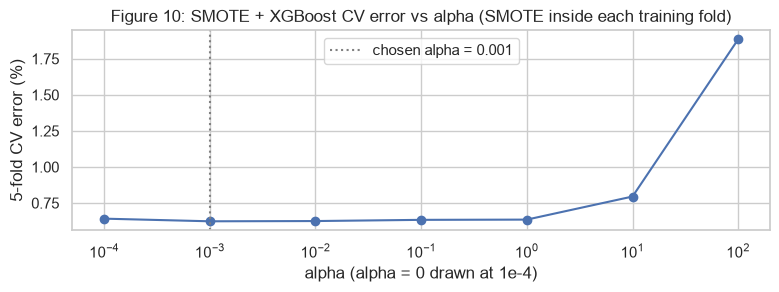

In [21]:
# right way: SMOTE inside the pipeline, so it only runs on the training folds
smote_pipe = make_pipeline(StandardScaler(), SMOTE(random_state=SEED), xgb_model())
smote_search = GridSearchCV(smote_pipe, {"xgbclassifier__reg_alpha": REG_ALPHAS}, cv=folds, scoring=CV_SCORING, refit="accuracy", n_jobs=-1).fit(train_X, train_y)
smote_alpha = smote_search.best_params_["xgbclassifier__reg_alpha"]
smote_cv_table = cv_table(smote_search)
smote_cv_error = smote_cv_table.loc[smote_search.best_index_, "CV error (%)"]
print(f"chosen alpha = {smote_alpha}, CV error = {smote_cv_error:.3f}%")
print(smote_cv_table.to_string(index=False))
plot_cv(smote_cv_table, smote_alpha, "Figure 10: SMOTE + XGBoost CV error vs alpha (SMOTE inside each training fold)")

train  error = 0.0017%, AUC = 1.0000, recall = 99.9000%, cost = 500
test   error = 1.0375%, AUC = 0.9922, recall = 85.8667%, cost = 27630


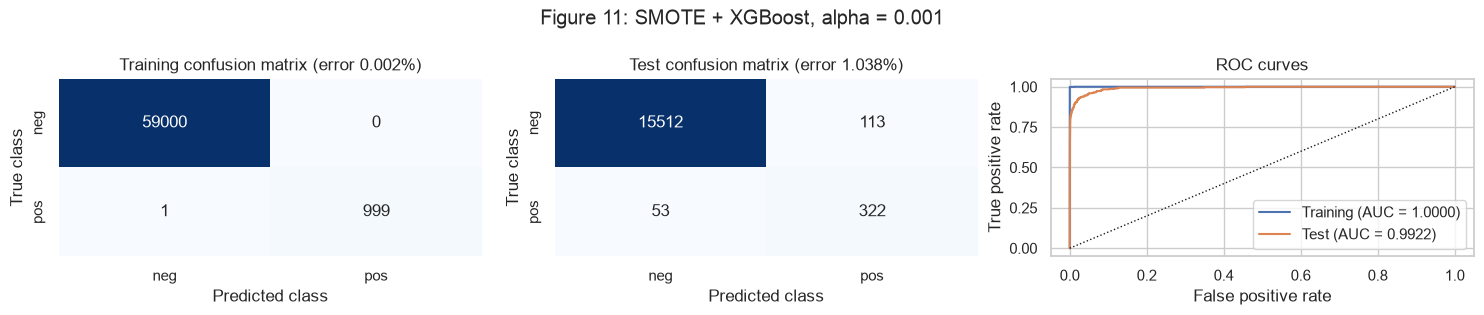

CV error = 0.623%, test error = 1.038%


In [22]:
# final model: SMOTE on the full training set, then XGBoost with the chosen alpha
smote_model = smote_search.best_estimator_

# training scores are on the original 60000 training rows
test_probs["SMOTE + XGBoost"] = report(smote_model, "SMOTE + XGBoost", train_X, test_X, f"Figure 11: SMOTE + XGBoost, alpha = {smote_alpha}")
print(f"CV error = {smote_cv_error:.3f}%, test error = {results['SMOTE + XGBoost']['test']['error (%)']:.3f}%")

In [23]:
# wrong way: SMOTE on the whole training set first, then cross-validate
smote_X, smote_y = SMOTE(random_state=SEED).fit_resample(StandardScaler().fit_transform(train_X), train_y)
print("Class counts after SMOTE:", np.bincount(smote_y))
wrong_scores = cross_val_score(xgb_model().set_params(reg_alpha=smote_alpha), smote_X, smote_y, cv=folds, scoring="accuracy", n_jobs=-1)
print(f"wrong-way CV error = {100 * (1 - wrong_scores.mean()):.3f}% (on {len(smote_y)} rows, half of them synthetic)")
print(f"right-way CV error = {smote_cv_error:.3f}%, test error = {results['SMOTE + XGBoost']['test']['error (%)']:.3f}%")

Class counts after SMOTE: [59000 59000]


wrong-way CV error = 0.231% (on 118000 rows, half of them synthetic)
right-way CV error = 0.623%, test error = 1.038%


In [24]:
# all models on the test set (TP = 375 - FN and TN = 15625 - FP)
oob_errors = [rf_oob, weighted_oob, balanced_oob]
summary_df = pd.DataFrame([res["test"] for res in results.values()], index=list(results)).drop(columns=["TP", "TN"])
summary_df = summary_df.rename(columns={"error (%)": "test error (%)", "AUC": "test AUC"})
summary_df.insert(0, "CV / OOB error (%)", oob_errors + [xgb_cv_error, smote_cv_error])
summary_df.insert(0, "train error (%)", [res["train"]["error (%)"] for res in results.values()])
summary_df

,train error (%),CV / OOB error (%),test error (%),test AUC,FN,FP,recall (%),cost
Random forest,0.0000,0.5800,0.7625,0.9943,103,19,72.5333,51690
Weighted random forest,0.0000,0.7533,1.0750,0.9943,159,13,57.6000,79630
Balanced random forest,4.2867,4.4250,4.1562,0.9930,7,658,98.1333,10080
XGBoost,0.0017,0.5183,0.5875,0.9952,78,16,79.2000,39160
SMOTE + XGBoost,0.0017,0.6233,1.0375,0.9922,53,113,85.8667,27630


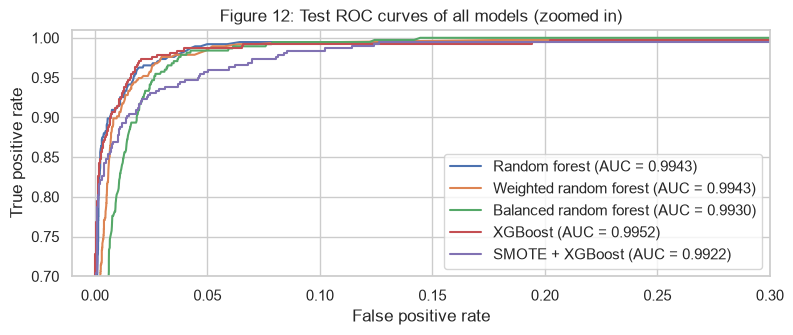

In [25]:
plt.figure(figsize=(9, 3.2))
for name, prob in test_probs.items():
    fpr, tpr, _ = roc_curve(test_y, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(test_y, prob):.4f})")
plt.plot([0, 1], [0, 1], "k:", lw=1)
plt.xlim(-0.01, 0.3)
plt.ylim(0.7, 1.01)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Figure 12: Test ROC curves of all models (zoomed in)")
plt.legend(loc="lower right")
plt.show()

**Answer.** With SMOTE inside the CV folds, CV picks **alpha = 0.001**, and the curve in Figure 10 is again flat up to alpha = 1.

SMOTE catches 25 more failures (recall 85.9% against 79.2%) but adds 97 false alarms. The test error and AUC get a little worse, but the **cost drops by 29%**. The effect is smaller than for the balanced forest in (d), because the boosted trees still fit the training set almost perfectly and the synthetic positives sit between real ones.

**Doing the CV the wrong way gives a CV error of only 0.231%**, about a third of the right-way estimate (0.623%) and about a quarter of the test error (1.038%). The held-out folds contain synthetic rows made from rows the model was trained on, and they are half positive instead of 1.7%. The right-way estimate is much closer to the test error.

Overall, XGBoost without compensation is best by error and AUC, while the compensated models are better by the challenge cost, and the balanced forest is best by far (Figure 12 and the table above).

## 2. ISLR 6.6.3

*The coefficients minimize $\sum_{i=1}^n \big(y_i - \beta_0 - \sum_{j=1}^p \beta_j x_{ij}\big)^2$ subject to $\sum_{j=1}^p |\beta_j| \le s$. As $s$ increases from 0, which of i. to v. happens in (a) to (e)? i. Increase initially, and then eventually start decreasing in an inverted U shape. ii. Decrease initially, and then eventually start increasing in a U shape. iii. Steadily increase. iv. Steadily decrease. v. Remain constant.*

At $s = 0$ every $\beta_j$ is 0 and the model predicts $\bar y$. As $s$ grows the constraint loosens until the fit is least squares, so a larger $s$ **increases the flexibility**.

**(a)** *Training RSS.* **Answer. iv. Steadily decrease.** A larger $s$ gives a larger feasible set, so the training RSS can only go down, until the constraint stops binding and it stays at the least squares RSS.

**(b)** *Test RSS.* **Answer. ii. Decrease initially, and then eventually start increasing in a U shape.** At $s = 0$ the model ignores the predictors and the test RSS is high (large bias). It drops as the important coefficients come in, then rises again once the model fits noise and the variance grows faster than the bias falls.

**(c)** *Variance.* **Answer. iii. Steadily increase.** The constant fit at $s = 0$ has the lowest variance, and a larger $s$ lets the coefficients depend more on the training sample, up to the least squares variance.

**(d)** *Squared bias.* **Answer. iv. Steadily decrease.** The more the coefficients are allowed to move away from 0, the closer the fitted model can get to the true function, so the squared bias goes down (to the least squares bias, which is 0 if the true model is linear).

**(e)** *Irreducible error.* **Answer. v. Remain constant.** $\text{Var}(\varepsilon)$ is the noise in $Y$ around the true function. It does not depend on the model, so it does not change with $s$.

## 3. ISLR 6.6.5

*Ridge tends to give correlated variables similar coefficients, while the lasso may not. Let $n = p = 2$, $x_{11} = x_{12}$, $x_{21} = x_{22}$, $y_1 + y_2 = 0$, $x_{11} + x_{21} = 0$ and $x_{12} + x_{22} = 0$, so that $\hat\beta_0 = 0$.*

Write $x_{11} = x_{12} = x$, so $x_{21} = x_{22} = -x$ and $y_2 = -y_1$ (assume $x \ne 0$ and $\lambda > 0$). Then both predictions are $\hat y_1 = (\beta_1 + \beta_2)x$ and $\hat y_2 = -(\beta_1 + \beta_2)x$, and the RSS is
$$(y_1 - (\beta_1 + \beta_2)x)^2 + (-y_1 + (\beta_1 + \beta_2)x)^2 = 2\big(y_1 - (\beta_1 + \beta_2)x\big)^2.$$
The RSS depends on $\beta_1$ and $\beta_2$ only through their sum.

**(a)** *Write out the ridge optimization problem.* **Answer.** Minimize $\sum_{i=1}^{2}(y_i - \beta_1 x_{i1} - \beta_2 x_{i2})^2 + \lambda(\beta_1^2 + \beta_2^2)$ over $\beta_1, \beta_2$, which in this setting is
$$\min_{\beta_1, \beta_2} \  2\big(y_1 - (\beta_1 + \beta_2)x\big)^2 + \lambda(\beta_1^2 + \beta_2^2).$$

**(b)** *Argue that the ridge estimates satisfy $\hat\beta_1 = \hat\beta_2$.* **Answer.** Setting the partial derivatives to 0:
$$\frac{\partial}{\partial \beta_1}: \  -4x\big(y_1 - (\beta_1 + \beta_2)x\big) + 2\lambda\beta_1 = 0, \qquad \frac{\partial}{\partial \beta_2}: \  -4x\big(y_1 - (\beta_1 + \beta_2)x\big) + 2\lambda\beta_2 = 0.$$
The first terms are the same, so subtracting gives $2\lambda(\beta_1 - \beta_2) = 0$, and since $\lambda > 0$, $\hat\beta_1 = \hat\beta_2$. The objective is strictly convex, so this is the unique minimum, and plugging in $\beta_1 = \beta_2 = \beta$ gives $4xy_1 = (8x^2 + 2\lambda)\beta$, so
$$\hat\beta_1 = \hat\beta_2 = \frac{2xy_1}{4x^2 + \lambda}.$$
Put simply, for a fixed sum $\beta_1 + \beta_2 = c$ the RSS is fixed and $\beta_1^2 + \beta_2^2$ is smallest at $\beta_1 = \beta_2 = c/2$, so ridge splits the weight evenly between the two identical predictors.

**(c)** *Write out the lasso optimization problem.* **Answer.** Minimize $\sum_{i=1}^{2}(y_i - \beta_1 x_{i1} - \beta_2 x_{i2})^2 + \lambda(|\beta_1| + |\beta_2|)$ over $\beta_1, \beta_2$, which in this setting is
$$\min_{\beta_1, \beta_2} \  2\big(y_1 - (\beta_1 + \beta_2)x\big)^2 + \lambda(|\beta_1| + |\beta_2|).$$

**(d)** *Argue that the lasso solution is not unique, and describe the solutions.* **Answer.** Let $c = \beta_1 + \beta_2$. By the triangle inequality $|\beta_1| + |\beta_2| \ge |c|$, with equality exactly when $\beta_1$ and $\beta_2$ have the same sign (or one is 0). So the objective is at least $2(y_1 - cx)^2 + \lambda|c|$, every same-sign pair with sum $c$ reaches it, and the problem reduces to a one-dimensional lasso in $c$ with the soft-thresholded solution
$$\hat c = \text{sign}\!\left(\frac{y_1}{x}\right)\max\!\left(\left|\frac{y_1}{x}\right| - \frac{\lambda}{4x^2}, \  0\right).$$
If $\hat c = 0$ the only solution is $\hat\beta_1 = \hat\beta_2 = 0$. Otherwise **every point on the segment**
$$\hat\beta_1 + \hat\beta_2 = \hat c, \qquad \hat\beta_1, \hat\beta_2 \text{ both } \ge 0 \text{ (if } \hat c > 0\text{) or both } \le 0 \text{ (if } \hat c < 0\text{)}$$
is a solution, for example $(\hat c, 0)$, $(0, \hat c)$ and $(\hat c/2, \hat c/2)$. Geometrically, the RSS contours $\beta_1 + \beta_2 = \text{const}$ are parallel to an edge of the lasso diamond $|\beta_1| + |\beta_2| \le s$, so the smallest contour touches the diamond along a whole edge instead of at one point. The code below checks this with numbers.

In [26]:
# numerical check with x = 1, y1 = 3, lambda = 2
X_VALUE, Y1, LAMBDA = 1.0, 3.0, 2.0

def objective(b1, b2, penalty):
    # RSS in this setting plus lambda times the ridge or lasso penalty
    return 2 * (Y1 - (b1 + b2) * X_VALUE) ** 2 + LAMBDA * penalty

ridge_beta = 2 * X_VALUE * Y1 / (4 * X_VALUE ** 2 + LAMBDA)
c_hat = np.sign(Y1 / X_VALUE) * max(abs(Y1 / X_VALUE) - LAMBDA / (4 * X_VALUE ** 2), 0)
print(f"ridge: beta1 = beta2 = {ridge_beta:.4f}, objective = {objective(ridge_beta, ridge_beta, 2 * ridge_beta ** 2):.4f}")
print(f"ridge: objective at (c, 0) = {objective(2 * ridge_beta, 0, (2 * ridge_beta) ** 2):.4f}")
print(f"lasso: c_hat = {c_hat:.4f}")
for b1 in np.linspace(0, c_hat, 5):
    print(f"  beta1 = {b1:.4f}, beta2 = {c_hat - b1:.4f}, objective = {objective(b1, c_hat - b1, abs(b1) + abs(c_hat - b1)):.4f}")

ridge: beta1 = beta2 = 1.0000, objective = 6.0000
ridge: objective at (c, 0) = 10.0000
lasso: c_hat = 2.5000
  beta1 = 0.0000, beta2 = 2.5000, objective = 5.5000
  beta1 = 0.6250, beta2 = 1.8750, objective = 5.5000
  beta1 = 1.2500, beta2 = 1.2500, objective = 5.5000
  beta1 = 1.8750, beta2 = 0.6250, objective = 5.5000
  beta1 = 2.5000, beta2 = 0.0000, objective = 5.5000


## 4. ISLR 8.4.5

*Trees fit to ten bootstrapped samples give these estimates of $P(\text{Class is Red} \mid X)$ for one value of $X$:*
$$0.1, \  0.15, \  0.2, \  0.2, \  0.55, \  0.6, \  0.6, \  0.65, \  0.7, \  0.75.$$
*What is the final class under majority vote, and under the average probability?* **Answer.**

- **Majority vote: Red.** Each tree votes Red when its estimate is above 0.5. Six estimates (0.55, 0.6, 0.6, 0.65, 0.7, 0.75) are above 0.5 and four are below, so Red wins 6 to 4.
- **Average probability: Green.** The average is $(0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75)/10 = 4.5/10 = 0.45 < 0.5$, so the class is Green.

The two rules disagree because the four Green votes are very confident (0.1 to 0.2), while the six Red votes are only a little above 0.5.

In [27]:
# check of the two rules
red_probs = np.array([0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75])
print(f"Red votes: {(red_probs > 0.5).sum()} of {len(red_probs)} -> majority vote: {'Red' if (red_probs > 0.5).sum() > len(red_probs) / 2 else 'Green'}")
print(f"Average probability: {red_probs.mean():.2f} -> {'Red' if red_probs.mean() > 0.5 else 'Green'}")

Red votes: 6 of 10 -> majority vote: Red
Average probability: 0.45 -> Green


## 5. ISLR 9.7.3

*Maximal margin classifier on a toy data set.*

**(a)** *Sketch the $n = 7$ observations: obs. 1 (3, 4), 2 (2, 2), 3 (4, 4) and 4 (1, 4) are Red, and obs. 5 (2, 1), 6 (4, 3) and 7 (4, 1) are Blue (coordinates are $(X_1, X_2)$).* **Answer.** The observations are plotted in Figure 13 (panel a), after part (h).

In [28]:
OBS = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
LABELS = np.array(["Red", "Red", "Red", "Red", "Blue", "Blue", "Blue"])
COLORS = {"Red": "tab:red", "Blue": "tab:blue"}
LINE_X = np.linspace(0, 5, 2)

def plot_observations(ax):
    for label in ["Red", "Blue"]:
        points = OBS[LABELS == label]
        ax.scatter(points[:, 0], points[:, 1], c=COLORS[label], s=70, label=label, zorder=3)
    for i, (x1, x2) in enumerate(OBS, start=1):
        ax.annotate(str(i), (x1, x2), textcoords="offset points", xytext=(6, 4), fontsize=9)
    ax.set(xlim=(0, 5), ylim=(0, 5), xlabel="X1", ylabel="X2", aspect="equal")


**(b)** *Sketch the optimal separating hyperplane and give its equation in the form (9.1).* **Answer.** The closest opposite-class pairs are obs. 2 (2, 2) and 5 (2, 1), and obs. 3 (4, 4) and 6 (4, 3), each one unit apart vertically. The red pair lies on $X_2 = X_1$ and the blue pair on the parallel line $X_2 = X_1 - 1$, so the maximal margin hyperplane is the line halfway between them, $X_2 = X_1 - 0.5$, i.e. $0.5 - X_1 + X_2 = 0$. In the form (9.1), $\beta_0 + \beta_1 X_1 + \beta_2 X_2 = 0$ with $\beta_0 = 0.5$, $\beta_1 = -1$, $\beta_2 = 1$. The hard-margin SVM fit below gives the same line.

**(c)** *Give the classification rule ("Classify to Red if $\beta_0 + \beta_1 X_1 + \beta_2 X_2 > 0$, and to Blue otherwise") with the values of $\beta_0$, $\beta_1$ and $\beta_2$.* **Answer.** Classify to **Red if $0.5 - X_1 + X_2 > 0$** and to Blue otherwise, so $\beta_0 = 0.5$, $\beta_1 = -1$, $\beta_2 = 1$. With the normalization $\beta_1^2 + \beta_2^2 = 1$ of (9.11) this is $\beta_0 = 0.5/\sqrt 2 \approx 0.354$, $\beta_1 = -1/\sqrt 2 \approx -0.707$, $\beta_2 = 1/\sqrt 2 \approx 0.707$. Check: obs. 4 (1, 4) gives $0.5 - 1 + 4 = 3.5 > 0$ (Red) and obs. 7 (4, 1) gives $0.5 - 4 + 1 = -2.5 < 0$ (Blue).

**(d)** *Indicate the margin on the sketch.* **Answer.** The margin lies between the dashed lines $X_2 = X_1$ (through the red support vectors) and $X_2 = X_1 - 1$ (through the blue ones) in Figure 13 (panel b). Its width on each side of the hyperplane is $M = 0.5/\sqrt{1^2 + 1^2} = 1/(2\sqrt 2) \approx 0.354$.

**(e)** *Indicate the support vectors.* **Answer.** The support vectors are the four points on the margin: **obs. 2 (2, 2) and 3 (4, 4)** (Red) and **obs. 5 (2, 1) and 6 (4, 3)** (Blue). They are circled in Figure 13 (panel b).

In [29]:
# hard-margin linear SVM (a very large C), with Red = +1 and Blue = -1
svm = SVC(kernel="linear", C=1e10).fit(OBS, np.where(LABELS == "Red", 1, -1))
beta = np.r_[svm.intercept_, svm.coef_[0]]
print("beta0, beta1, beta2 =", np.round(beta / svm.coef_[0][1], 4), "(scaled so beta2 = 1)")
print("normalized:", np.round(beta / np.linalg.norm(svm.coef_[0]), 4))
print(f"margin M = {1 / np.linalg.norm(svm.coef_[0]):.4f}")
print("support vectors (obs.):", sorted(int(i) + 1 for i in svm.support_))

beta0, beta1, beta2 = [ 0.5 -1.   1. ] (scaled so beta2 = 1)
normalized: [ 0.3536 -0.7071  0.7071]
margin M = 0.3537
support vectors (obs.): [2, 3, 5, 6]


**(f)** *Argue that a slight move of obs. 7 would not change the maximal margin hyperplane.* **Answer.** Obs. 7 (4, 1) is not a support vector. Its distance to the hyperplane is $|0.5 - 4 + 1|/\sqrt 2 = 2.5/\sqrt 2 \approx 1.77$, far more than the margin $0.354$. The hyperplane depends only on the constraints $y_i(\beta_0 + \beta_1 x_{i1} + \beta_2 x_{i2}) \ge M$ that are active at the solution, which are those of obs. 2, 3, 5 and 6. A small move keeps obs. 7 outside the margin on the Blue side, so its constraint stays inactive and the solution does not change. It would only matter if obs. 7 were moved into the margin.

**(g)** *Sketch a separating hyperplane that is not optimal and give its equation.* **Answer.** For example $0.3 - X_1 + X_2 = 0$ (the line $X_2 = X_1 - 0.3$, Figure 13 panel g). It still separates the classes (the red points give 0.3, 0.3, 1.3, 3.3, all $> 0$, and the blue points give $-0.7$, $-0.7$, $-2.7$, all $< 0$), but it is closer to the red points than to the blue ones. Its distance to obs. 2 and 3 is only $0.3/\sqrt 2 \approx 0.21$, less than the optimal margin $0.354$, so it is not optimal.

**(h)** *Add one observation so that the classes are no longer separable by a hyperplane.* **Answer.** Add a **Red observation at (4, 2)** (Figure 13 panel h). It lies on the segment between the blue obs. 6 (4, 3) and 7 (4, 1), inside the convex hull of the blue points. Any line with all blue points on one side has that whole triangle, including (4, 2), on the same side, so no line can separate the classes.

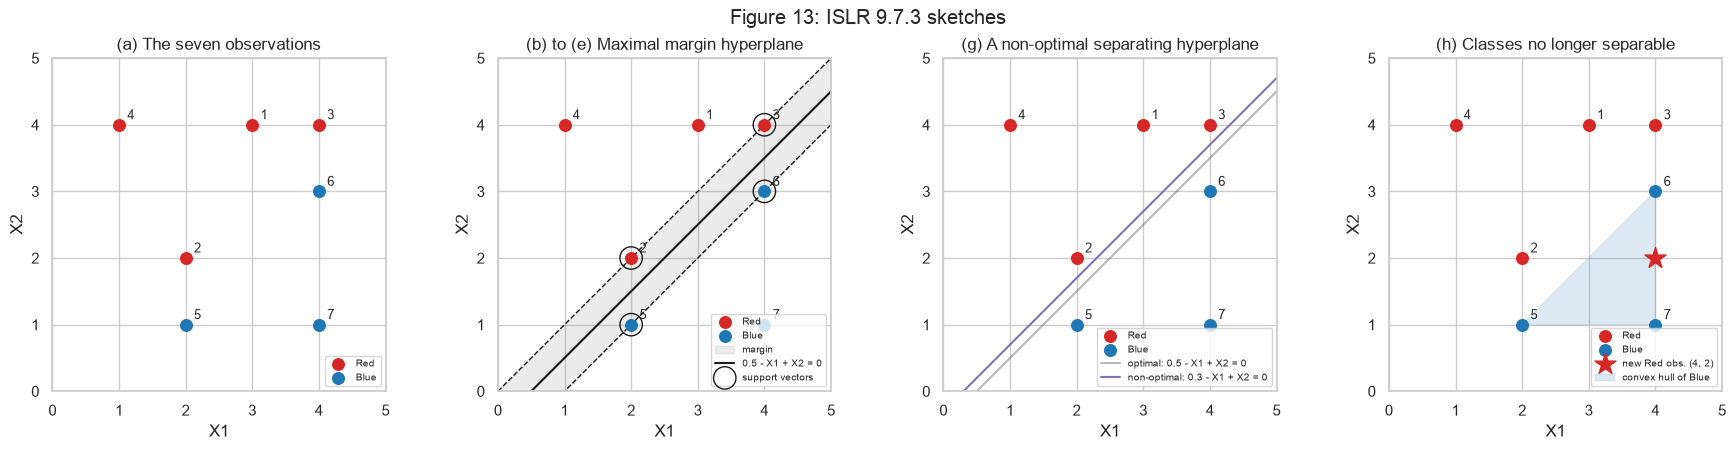

In [30]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))

# (a) the observations
plot_observations(axes[0])

# (b) to (e) hyperplane, margin and support vectors
plot_observations(axes[1])
axes[1].fill_between(LINE_X, LINE_X - 1, LINE_X, color="gray", alpha=0.15, label="margin")
axes[1].plot(LINE_X, LINE_X - 0.5, "k-", label="0.5 - X1 + X2 = 0")
axes[1].plot(LINE_X, LINE_X, "k--", lw=1)
axes[1].plot(LINE_X, LINE_X - 1, "k--", lw=1)
support_points = OBS[svm.support_]
axes[1].scatter(support_points[:, 0], support_points[:, 1], s=260, facecolors="none", edgecolors="k", label="support vectors", zorder=4)

# (g) a separating line that is not optimal
plot_observations(axes[2])
axes[2].plot(LINE_X, LINE_X - 0.5, "k-", alpha=0.3, label="optimal: 0.5 - X1 + X2 = 0")
axes[2].plot(LINE_X, LINE_X - 0.3, "m-", label="non-optimal: 0.3 - X1 + X2 = 0")

# (h) one more red point makes the classes non-separable
plot_observations(axes[3])
axes[3].scatter([4], [2], c="tab:red", marker="*", s=250, label="new Red obs. (4, 2)", zorder=4)
axes[3].fill(OBS[LABELS == "Blue"][:, 0], OBS[LABELS == "Blue"][:, 1], color="tab:blue", alpha=0.15, label="convex hull of Blue")

titles = ["(a) The seven observations", "(b) to (e) Maximal margin hyperplane", "(g) A non-optimal separating hyperplane", "(h) Classes no longer separable"]
for ax, title in zip(axes, titles):
    ax.legend(loc="lower right", fontsize=7)
    ax.set_title(title)
fig.suptitle("Figure 13: ISLR 9.7.3 sketches")
plt.tight_layout()
plt.show()

### References

1. UCI Machine Learning Repository, *APS Failure at Scania Trucks Data Set*: https://archive.ics.uci.edu/dataset/421/aps+failure+at+scania+trucks
2. R. J. A. Little, D. B. Rubin, *Statistical Analysis with Missing Data*, 3rd ed., Wiley (2019).
3. S. van Buuren, K. Groothuis-Oudshoorn, "mice: Multivariate Imputation by Chained Equations in R," *Journal of Statistical Software*, 45(3) (2011), 1-67.
4. L. Breiman, "Random forests," *Machine Learning*, 45 (2001), 5-32.
5. C. Chen, A. Liaw, L. Breiman, "Using random forest to learn imbalanced data," Technical Report 666, Department of Statistics, UC Berkeley (2004).
6. T. Chen, C. Guestrin, "XGBoost: A scalable tree boosting system," *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (2016), 785-794.
7. N. V. Chawla, K. W. Bowyer, L. O. Hall, W. P. Kegelmeyer, "SMOTE: Synthetic minority over-sampling technique," *Journal of Artificial Intelligence Research*, 16 (2002), 321-357.
8. G. Lemaitre, F. Nogueira, C. K. Aridas, "Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning," *Journal of Machine Learning Research*, 18(17) (2017), 1-5.
9. T. Fawcett, "An introduction to ROC analysis," *Pattern Recognition Letters*, 27 (2006), 861-874.
10. G. James, D. Witten, T. Hastie, R. Tibshirani, *An Introduction to Statistical Learning* (ISLR), Ch. 4.1 (Figure 4.1), Ch. 5.2 (the bootstrap), Ch. 6.2 (ridge regression and the lasso), Ch. 8 (bagging, out-of-bag error, random forests, boosting) and Ch. 9.1 (the maximal margin classifier).
11. T. Hastie, R. Tibshirani, J. Friedman, *The Elements of Statistical Learning*, 2nd ed., Sec. 7.10.2 "The Wrong and Right Way to Do Cross-validation."
12. XGBoost documentation, "XGBoost Parameters": https://xgboost.readthedocs.io/en/stable/parameter.html
13. scikit-learn documentation, `RandomForestClassifier`: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
14. imbalanced-learn documentation, `BalancedRandomForestClassifier` and `SMOTE`: https://imbalanced-learn.org/stable/